In [1]:
import tensorflow

In [2]:
print(tensorflow.__version__)

2.21.0


In [3]:
#mounting the google drive for importing the data
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [4]:
!ls gdrive/MyDrive/Datasets

GoogleNews-vectors-negative300.bin.gz  pneomonia.zip


In [5]:
!unzip gdrive/MyDrive/Datasets/pneomonia.zip

Streaming output truncated to the last 5000 lines.
  inflating: chest_xray/train/NORMAL/IM-0435-0001-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0435-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0437-0001-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0437-0001-0002.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0437-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0438-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0439-0001-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0439-0001-0002.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0439-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0440-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0441-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0442-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0444-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0445-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0446-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0447-0001.jpeg  
  inflating:

In [6]:
#!ls /content/pneumonia/

In [7]:
#!find /content/pneumonia -maxdepth 3 -type d

In [8]:
# import the libraries

import numpy as np

import matplotlib.pyplot as plt
import cv2
import os

In [9]:
# setting the training data dictionary
DataDir = "/content/chest_xray/train"

In [10]:
# initialize the category of classification
CATEGORIES = ["PNEUMONIA","NORMAL"]


In [11]:
!ls /content/chest_xray

chest_xray  __MACOSX  test  train  val


In [12]:
!ls /content/chest_xray/test

NORMAL	PNEUMONIA


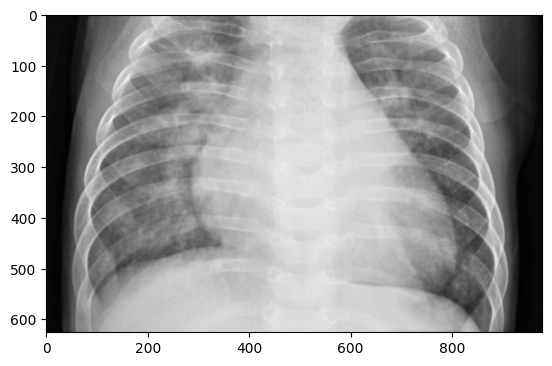

In [13]:
# convert the image into grayscale
for i in CATEGORIES:
  path=os.path.join(DataDir,i)
  for img in os.listdir(path):
    img_array=cv2.imread(os.path.join(path,img),cv2.IMREAD_GRAYSCALE)
    plt.imshow(img_array,cmap="gray")
    plt.show()
    break
  break

In [14]:
# Initialize the size of the image so that every image should be in the same directory
img_size = 100

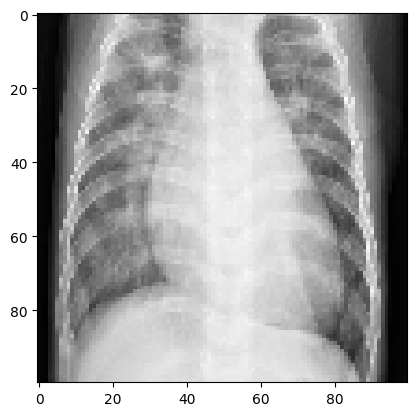

In [15]:
#image after resize and gray scele
new_array = cv2.resize(img_array,(img_size,img_size))
plt.imshow(new_array,cmap='gray')
plt.show()

In [16]:
training_data = []

In [17]:
# Create training data: each image is stored together with its label
def create_training_data():
    training_data.clear()  # Prevent duplicate data if this cell is run again

    for i in CATEGORIES:
        path = os.path.join(DataDir, i)
        class_num = CATEGORIES.index(i)

        for img in os.listdir(path):
            image_path = os.path.join(path, img)
            try:
                img_array = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

                # Skip files that OpenCV cannot read
                if img_array is None:
                    print("Could not read image:", image_path)
                    continue

                new_array = cv2.resize(img_array, (img_size, img_size))
                training_data.append([new_array, class_num])

            except Exception as e:
                print("Error processing", image_path, ":", e)


In [18]:
create_training_data()

In [19]:
print(len(training_data))

5216


In [20]:
import random
random.shuffle(training_data)
for sample in training_data[:10]:
  print(sample)

[array([[ 0,  0,  0, ...,  0,  0,  0],
       [ 0,  0,  0, ...,  1,  0,  0],
       [ 0,  0,  0, ..., 12,  8,  5],
       ...,
       [ 0,  0,  0, ..., 22,  0,  0],
       [ 0,  0,  0, ..., 28,  0,  0],
       [ 0,  0,  0, ..., 26,  0,  0]], shape=(100, 100), dtype=uint8), 1]
[array([[132, 135, 130, ..., 130, 134, 132],
       [128, 126, 129, ..., 133, 137, 136],
       [131, 123, 126, ..., 147, 141, 143],
       ...,
       [  0,   0,   0, ...,   0,   0,   0],
       [  0,   0,   0, ...,   0,   0,   0],
       [  0,   0,   0, ...,   0,   0,   0]], shape=(100, 100), dtype=uint8), 0]
[array([[ 34,  38,  18, ..., 170, 193,  41],
       [ 32,  31,  25, ..., 181, 185,  41],
       [ 41,  30,  33, ..., 173, 184,  33],
       ...,
       [132,  28,  28, ...,  41,  44,  43],
       [ 26,  16,  33, ...,  41,  46,  48],
       [ 28, 112,  28, ...,  39,  43,  47]], shape=(100, 100), dtype=uint8), 0]
[array([[46, 33, 25, ..., 47, 51, 48],
       [81, 53, 31, ..., 60, 63, 61],
       [86, 83, 69, 

In [21]:
X = []
Y = []


In [22]:
# Split features and labels. Reset both arrays before filling them.
X = []
Y = []

for features, labels in training_data:
    X.append(features)
    Y.append(labels)

# Check that every image has one matching label
assert len(X) == len(Y), f"Training mismatch: {len(X)} images and {len(Y)} labels"


In [23]:
print(X[0].reshape(-1,img_size,img_size,1))

[[[[ 0]
   [ 0]
   [ 0]
   ...
   [ 0]
   [ 0]
   [ 0]]

  [[ 0]
   [ 0]
   [ 0]
   ...
   [ 1]
   [ 0]
   [ 0]]

  [[ 0]
   [ 0]
   [ 0]
   ...
   [12]
   [ 8]
   [ 5]]

  ...

  [[ 0]
   [ 0]
   [ 0]
   ...
   [22]
   [ 0]
   [ 0]]

  [[ 0]
   [ 0]
   [ 0]
   ...
   [28]
   [ 0]
   [ 0]]

  [[ 0]
   [ 0]
   [ 0]
   ...
   [26]
   [ 0]
   [ 0]]]]


In [24]:
Y=np.array(Y)


In [25]:
# reshape the feature for make it compatible with tensorflow
X=np.array(X).reshape(-1,img_size,img_size,1)

In [26]:
# As we do for trainin data similarity doing with validation data
validation_data = []
DataDir_val = "/content/chest_xray/val"

In [27]:
# Create validation data using the same preprocessing as training data
def create_validating_data():
    validation_data.clear()  # Prevent duplicate data if this cell is run again

    for i in CATEGORIES:
        path = os.path.join(DataDir_val, i)
        class_num = CATEGORIES.index(i)

        for img in os.listdir(path):
            image_path = os.path.join(path, img)
            try:
                img_array = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

                if img_array is None:
                    print("Could not read validation image:", image_path)
                    continue

                new_array = cv2.resize(img_array, (img_size, img_size))
                validation_data.append([new_array, class_num])

            except Exception as e:
                print("Error processing", image_path, ":", e)


In [28]:
create_validating_data()
print(len(validation_data))

16


In [29]:
import random
random.shuffle(validation_data)
for sample in validation_data[:10]:
    print(sample)

[array([[  2,  56,  64, ...,  16,   7,   2],
       [242,  56,  65, ...,  10,   5,   1],
       [ 49,  59,  63, ...,   7,   4,   0],
       ...,
       [  0,   0,   0, ...,  38,  41,  34],
       [  0,   0,   0, ...,  28,  23,  17],
       [  0,   0,   0, ...,   1,   0,   0]], shape=(100, 100), dtype=uint8), 1]
[array([[ 0,  5, 16, ..., 79, 47, 29],
       [ 0,  3, 15, ..., 78, 47, 27],
       [ 0,  3, 16, ..., 77, 52, 25],
       ...,
       [ 1,  1,  0, ...,  2,  2,  2],
       [ 1,  1,  0, ...,  1,  2,  2],
       [ 1,  1,  1, ...,  2,  2,  2]], shape=(100, 100), dtype=uint8), 0]
[array([[  0,  85, 102, ...,  95,  73,  51],
       [ 50,  77,  90, ...,  83,  60,  39],
       [ 44,  62,  95, ...,  76,  55,  34],
       ...,
       [  0,   0,   0, ...,   0,   0,   0],
       [  0,   0,   0, ...,   0,   0,   0],
       [  0,   0,   0, ...,   0,   0,   0]], shape=(100, 100), dtype=uint8), 1]
[array([[  2, 107,  75, ...,   0,   3,  10],
       [ 59, 105,  51, ...,   2,   0,  21],
       [

In [30]:
X_val = []
Y_val = []


In [31]:
# Split validation features and labels
X_val = []
Y_val = []

for features, labels in validation_data:
    X_val.append(features)
    Y_val.append(labels)

assert len(X_val) == len(Y_val), (
    f"Validation mismatch: {len(X_val)} images and {len(Y_val)} labels"
)


In [32]:
Y_val=np.array(Y_val)
X_val=np.array(X_val).reshape(-1,img_size,img_size,1)

In [33]:
#Import the libraries for training the mode and adding the neural network layers

import tensorflow as tf
from keras.models import Sequential
from keras.layers import Dense, Dropout, Activation, Flatten
from keras.layers import Conv2D, MaxPooling2D
import pickle

In [34]:
X=X/255.0
X_val=X_val/255.0

In [35]:
X.shape

(5216, 100, 100, 1)

In [36]:
X_val.shape

(16, 100, 100, 1)

In [37]:
# Initialize the NN layers for training the model
model = Sequential()

In [38]:
model.add(Conv2D(64,(3,3),input_shape=X.shape[1:]))
model.add(Activation("relu"))
model.add(MaxPooling2D(pool_size=(2,2)))
model.add(Dropout(.2))


model.add(Conv2D(128,(3,3)))
model.add(Activation("relu"))
model.add(MaxPooling2D(pool_size=(2,2)))
model.add(Dropout(.2))

model.add(Conv2D(256,(3,3)))
model.add(Activation("relu"))
model.add(MaxPooling2D(pool_size=(2,2)))
model.add(Dropout(.2))

model.add(Flatten())
model.add(Dense(64))

model.add(Dropout(.5))

model.add(Dense(1))
model.add(Activation("sigmoid"))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [39]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 98, 98, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 98, 98, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 49, 49, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 49, 49, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 47, 47, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 47, 47, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 23, 23, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 23, 23, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 21, 21, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 21, 21, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 10, 10, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 10, 10, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     1,638,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 1)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,008,193 (7.66 MB)

 Trainable params: 2,008,193 (7.66 MB)

 Non-trainable params: 0 (0.00 B)

In [40]:
model.compile(loss="binary_crossentropy",
             optimizer="adam",
             metrics=['accuracy'])

In [41]:
print("X images:", len(X))
print("Y labels:", len(Y))
print("X_val images:", len(X_val))
print("Y_val labels:", len(Y_val))

X images: 5216
Y labels: 5216
X_val images: 16
Y_val labels: 16


In [42]:
# Final check before training
print("Training images:", len(X))
print("Training labels:", len(Y))
print("Validation images:", len(X_val))
print("Validation labels:", len(Y_val))
print("X shape:", X.shape)
print("Y shape:", Y.shape)
print("X_val shape:", X_val.shape)
print("Y_val shape:", Y_val.shape)


Training images: 5216
Training labels: 5216
Validation images: 16
Validation labels: 16
X shape: (5216, 100, 100, 1)
Y shape: (5216,)
X_val shape: (16, 100, 100, 1)
Y_val shape: (16,)


In [43]:
# Make sure the data is consistent before fitting the model
assert len(X) == len(Y), "Training images and labels do not match"
assert len(X_val) == len(Y_val), "Validation images and labels do not match"
assert X.ndim == 4 and X.shape[1:] == (img_size, img_size, 1)
assert X_val.ndim == 4 and X_val.shape[1:] == (img_size, img_size, 1)

print("Dataset checks passed. Ready to train.")


Dataset checks passed. Ready to train.


In [44]:
# fitting the model with 10 epochs and using validation data we have created

model.fit(X,Y,batch_size=5,epochs=10,validation_data=(X_val,Y_val))

Epoch 1/10
1044/1044 ━━━━━━━━━━━━━━━━━━━━ 199s 189ms/step - accuracy: 0.8836 - loss: 0.2962 - val_accuracy: 0.7500 - val_loss: 0.4389
Epoch 2/10
1044/1044 ━━━━━━━━━━━━━━━━━━━━ 200s 187ms/step - accuracy: 0.9505 - loss: 0.1460 - val_accuracy: 1.0000 - val_loss: 0.0575
Epoch 3/10
1044/1044 ━━━━━━━━━━━━━━━━━━━━ 204s 195ms/step - accuracy: 0.9571 - loss: 0.1138 - val_accuracy: 0.6250 - val_loss: 0.5298
Epoch 4/10
1044/1044 ━━━━━━━━━━━━━━━━━━━━ 261s 195ms/step - accuracy: 0.9643 - loss: 0.1061 - val_accuracy: 1.0000 - val_loss: 0.0948
Epoch 5/10
1044/1044 ━━━━━━━━━━━━━━━━━━━━ 257s 189ms/step - accuracy: 0.9651 - loss: 0.1009 - val_accuracy: 0.6875 - val_loss: 0.6206
Epoch 6/10
1044/1044 ━━━━━━━━━━━━━━━━━━━━ 196s 188ms/step - accuracy: 0.9712 - loss: 0.0841 - val_accuracy: 0.9375 - val_loss: 0.1571
Epoch 7/10
1044/1044 ━━━━━━━━━━━━━━━━━━━━ 202s 188ms/step - accuracy: 0.9684 - loss: 0.0792 - val_accuracy: 1.0000 - val_loss: 0.1790
Epoch 8/10
1044/1044 ━━━━━━━━━━━━━━━━━━━━ 193s 185ms/step - ac

In [45]:
# save the model
model.save(r"model_10.keras")

In [46]:
#import the libraries for testing the model

import cv2
import tensorflow as tf
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from keras.models import load_model

CATEGORIES = ['NORMAL','PNEUMONIA']

In [47]:
#Function for prepare the image for predict the class

def prepare(image):
  image_size =100
  #image_array = cv2.imread(image,cv2.IMREAD_GRAYSCALE)
  img = tf.keras.preprocessing.image.load_img(image,color_mode='grayscale',target_size=(image_size,image_size))
  new_array = tf.keras.preprocessing.image.img_to_array(img)
  return new_array.reshape(-1,img_size,img_size,1)


In [48]:
!ls /content/chest_xray/test/NORMAL/

IM-0001-0001.jpeg	   NORMAL2-IM-0173-0001-0001.jpeg
IM-0003-0001.jpeg	   NORMAL2-IM-0173-0001-0002.jpeg
IM-0005-0001.jpeg	   NORMAL2-IM-0195-0001.jpeg
IM-0006-0001.jpeg	   NORMAL2-IM-0196-0001.jpeg
IM-0007-0001.jpeg	   NORMAL2-IM-0198-0001.jpeg
IM-0009-0001.jpeg	   NORMAL2-IM-0199-0001.jpeg
IM-0010-0001.jpeg	   NORMAL2-IM-0201-0001.jpeg
IM-0011-0001-0001.jpeg	   NORMAL2-IM-0206-0001.jpeg
IM-0011-0001-0002.jpeg	   NORMAL2-IM-0207-0001.jpeg
IM-0011-0001.jpeg	   NORMAL2-IM-0210-0001.jpeg
IM-0013-0001.jpeg	   NORMAL2-IM-0213-0001.jpeg
IM-0015-0001.jpeg	   NORMAL2-IM-0217-0001.jpeg
IM-0016-0001.jpeg	   NORMAL2-IM-0219-0001.jpeg
IM-0017-0001.jpeg	   NORMAL2-IM-0221-0001.jpeg
IM-0019-0001.jpeg	   NORMAL2-IM-0222-0001.jpeg
IM-0021-0001.jpeg	   NORMAL2-IM-0229-0001.jpeg
IM-0022-0001.jpeg	   NORMAL2-IM-0232-0001.jpeg
IM-0023-0001.jpeg	   NORMAL2-IM-0233-0001.jpeg
IM-0025-0001.jpeg	   NORMAL2-IM-0237-0001.jpeg
IM-0027-0001.jpeg	   NORMAL2-IM-0238-0001.jpeg
IM-0028-0001.jpeg	   NORMAL2-IM-0241-000

In [49]:
model = tf.keras.models.load_model(r"model_10.keras")

In [50]:
image = "/content/chest_xray/test/NORMAL/IM-0085-0001.jpeg"



In [51]:
prediction = model.predict([prepare(image)/255.0])
print(prediction)

print(round(prediction[0][0]))
print(CATEGORIES[int(round(prediction[0][0]))])


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step
[[0.00026715]]
0
NORMAL


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: input_layer
Received: inputs=('Tensor(shape=(1, 100, 100, 1))',)
  warnings.warn(msg)


In [52]:

import os
import cv2
import numpy as np

test_dir = "/content/chest_xray/test"

test_data = []
CATEGORIES = ["PNEUMONIA", "NORMAL"]

for category in CATEGORIES:
    path = os.path.join(test_dir, category)
    class_num = CATEGORIES.index(category)

    for img in os.listdir(path):
        image_path = os.path.join(path, img)

        try:
            img_array = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

            if img_array is None:
                print("Could not read:", image_path)
                continue

            new_array = cv2.resize(img_array, (100, 100))
            test_data.append([new_array, class_num])

        except Exception as e:
            print("Error:", image_path, e)

print("Total test images:", len(test_data))


Total test images: 624


In [53]:

X_test = []
Y_test = []

for features, labels in test_data:
    X_test.append(features)
    Y_test.append(labels)

X_test = np.array(X_test).reshape(-1, 100, 100, 1)
Y_test = np.array(Y_test)

print("X_test shape:", X_test.shape)
print("Y_test shape:", Y_test.shape)

assert len(X_test) == len(Y_test), "Test data mismatch!"


X_test shape: (624, 100, 100, 1)
Y_test shape: (624,)


In [54]:

X_test = X_test / 255.0


In [55]:

test_loss, test_accuracy = model.evaluate(X_test, Y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)


20/20 ━━━━━━━━━━━━━━━━━━━━ 7s 316ms/step - accuracy: 0.7628 - loss: 1.0699
Test Loss: 1.0698603391647339
Test Accuracy: 0.7628205418586731


20/20 ━━━━━━━━━━━━━━━━━━━━ 6s 294ms/step
Accuracy: 0.7628205128205128

Classification Report:
              precision    recall  f1-score   support

   PNEUMONIA       0.73      0.99      0.84       390
      NORMAL       0.97      0.38      0.55       234

    accuracy                           0.76       624
   macro avg       0.85      0.69      0.69       624
weighted avg       0.82      0.76      0.73       624



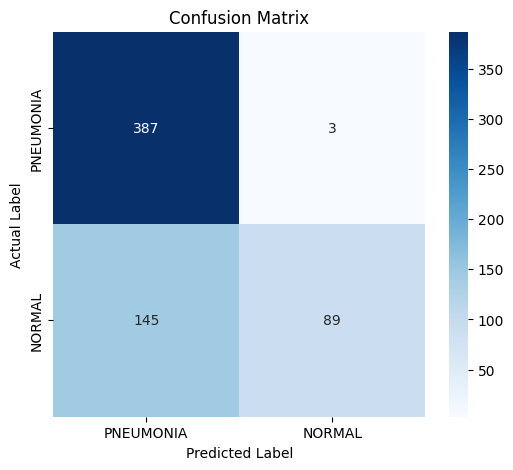

In [56]:

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)
import matplotlib.pyplot as plt
import seaborn as sns

# Get predictions
predictions = model.predict(X_test)

# Convert probabilities into class labels
Y_pred = (predictions.ravel() >= 0.5).astype(int)

# Calculate accuracy
print("Accuracy:", accuracy_score(Y_test, Y_pred))

# Classification report
print("\nClassification Report:")
print(classification_report(
    Y_test,
    Y_pred,
    target_names=CATEGORIES
))

# Confusion matrix
cm = confusion_matrix(Y_test, Y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=CATEGORIES,
    yticklabels=CATEGORIES
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix")
plt.show()


In [57]:

# Check actual test labels
print("Actual label distribution:")
print("NORMAL:", np.sum(Y_test == 0))
print("PNEUMONIA:", np.sum(Y_test == 1))

# Check predicted label distribution
print("\nPredicted label distribution:")
print("NORMAL:", np.sum(Y_pred == 0))
print("PNEUMONIA:", np.sum(Y_pred == 1))

# Check prediction probabilities
print("\nPrediction probabilities:")
print("Minimum:", predictions.min())
print("Maximum:", predictions.max())
print("Mean:", predictions.mean())

# Display confusion matrix
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(Y_test, Y_pred)
print("\nConfusion Matrix:")
print(cm)


Actual label distribution:
NORMAL: 390
PNEUMONIA: 234

Predicted label distribution:
NORMAL: 532
PNEUMONIA: 92

Prediction probabilities:
Minimum: 7.861064e-12
Maximum: 0.9999942
Mean: 0.1516135

Confusion Matrix:
[[387   3]
 [145  89]]


In [58]:
model.summary()
print("\nFinal layer:", model.layers[-1].get_config())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 98, 98, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 98, 98, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 49, 49, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 49, 49, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 47, 47, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 47, 47, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 23, 23, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 23, 23, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 21, 21, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 21, 21, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 10, 10, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 10, 10, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     1,638,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 1)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,024,581 (22.98 MB)

 Trainable params: 2,008,193 (7.66 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 4,016,388 (15.32 MB)


Final layer: {'name': 'activation_3', 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'float32'}, 'registered_name': None}, 'activation': 'sigmoid'}


# **Pre_Train Model**

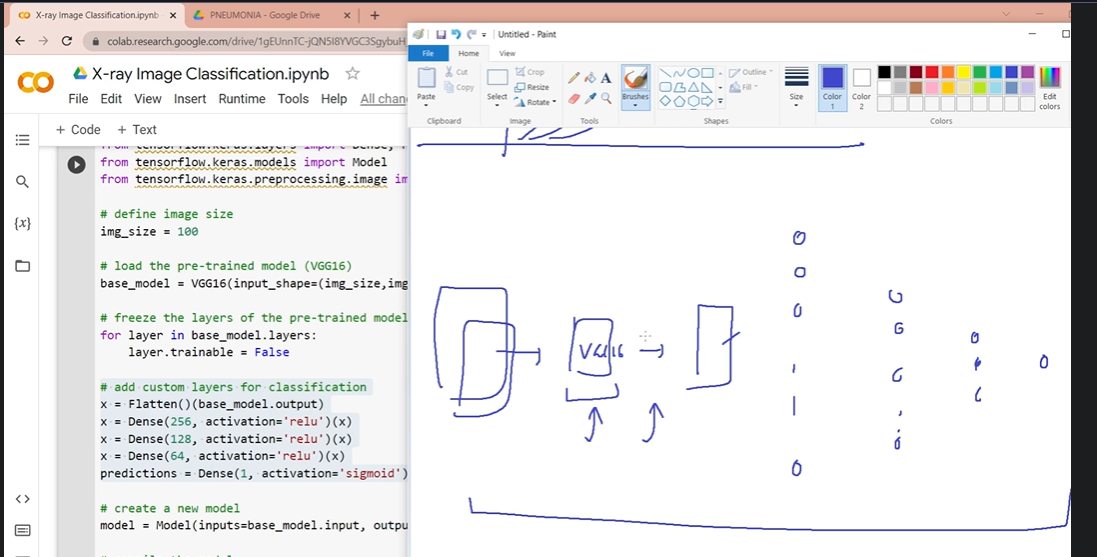

In [59]:
import tensorflow as tf
from tensorflow.keras.applications.vgg16 import VGG16
from tensorflow.keras.layers import Dense,Flatten
from tensorflow.keras.models import Model
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Image generator
img_size = 100

# load the pre train model
base_model = VGG16(input_shape=(img_size,img_size,3),include_top = False ,weights = 'imagenet')


# freeze the layer of pre train model
for layer in base_model.layers:
    layer.trainable = False

# add custom layers for classifications
x = Flatten()(base_model.output)
x = Dense(256,activation = 'relu')(x)
x = Dense(128,activation = 'relu')(x)
x = Dense(64,activation = 'relu')(x)
prediction = Dense(1,activation = 'sigmoid')(x)

# Create new Model
model = Model(inputs = base_model.input,outputs = prediction)

# Compile the model
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# define the image generator for training and validation data
train_datagen = ImageDataGenerator(
    rescale=1./255,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True
)

validation_datagen = ImageDataGenerator(rescale=1./25)

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [61]:
from sklearn.utils import validation
# specify the train and validation data directories
train_dir = '/content/chest_xray/train'
validation_dir = '/content/chest_xray/val'


# create the image generator for training and validation data
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(img_size, img_size),
    batch_size=32,
    class_mode='binary',

)

validation_generator = validation_datagen.flow_from_directory(
    validation_dir,
    target_size=(img_size, img_size),
    batch_size=32,
    class_mode='binary'
)

# train the model
model.fit(train_generator ,epochs = 2, validation_data=validation_generator)

# evaluate the model on test data

test_dir = '/content/chest_xray/test'
test_datagenerator = ImageDataGenerator(rescale=1./255)
test_generator = test_datagenerator.flow_from_directory(test_dir,target_size=(img_size,img_size),batch_size=32,class_mode='binary')
test_loss, test_acc = model.evaluate(test_generator)
print('Test accuracy:', test_acc)

Found 5216 images belonging to 2 classes.
Found 16 images belonging to 2 classes.
Epoch 1/2
163/163 ━━━━━━━━━━━━━━━━━━━━ 456s 3s/step - accuracy: 0.9427 - loss: 0.1524 - val_accuracy: 0.7500 - val_loss: 0.9802
Epoch 2/2
163/163 ━━━━━━━━━━━━━━━━━━━━ 494s 3s/step - accuracy: 0.9477 - loss: 0.1419 - val_accuracy: 0.6875 - val_loss: 1.0648
Found 624 images belonging to 2 classes.
20/20 ━━━━━━━━━━━━━━━━━━━━ 54s 3s/step - accuracy: 0.8638 - loss: 0.3501
Test accuracy: 0.8637820482254028


In [62]:
# Save the Pre Train model
import os

save_path = '/content/gdrive/MyDrive'

os.makedirs(save_path, exist_ok=True)

model.save(os.path.join(save_path, 'custom_pre_trained_model_10.keras'))

print("Model saved successfully in Google Drive!")

Model saved successfully in Google Drive!


In [65]:
model = tf.keras.models.load_model(r'/content/gdrive/MyDrive/custom_pre_trained_model_10.keras')

In [ ]:
model.summary()

In [66]:
# evaluate the model on test data

test_dir = '/content/chest_xray/test'
test_datagenerator = ImageDataGenerator(rescale=1./255)
test_generator = test_datagenerator.flow_from_directory(test_dir,target_size=(img_size,img_size),batch_size=32,class_mode='binary',shuffle=False)
test_loss, test_acc = model.evaluate(test_generator)
print('Test accuracy:', test_acc)

Found 624 images belonging to 2 classes.
20/20 ━━━━━━━━━━━━━━━━━━━━ 55s 3s/step - accuracy: 0.8638 - loss: 0.3501
Test accuracy: 0.8637820482254028


Saving normal_img_pneomonia.jfif to normal_img_pneomonia.jfif
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 249ms/step
Prediction: PNEUMONIA
Sigmoid output: 0.50469774


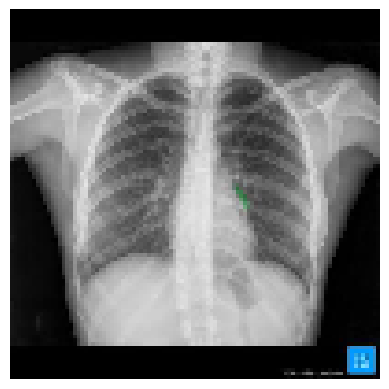

In [67]:
from google.colab import files
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Upload an X-ray image
uploaded = files.upload()
image_path = list(uploaded.keys())[0]

# Load and preprocess image
img = tf.keras.utils.load_img(
    image_path,
    target_size=(100, 100),
    color_mode='rgb'
)

img_array = tf.keras.utils.img_to_array(img)
img_array = img_array / 255.0
img_array = np.expand_dims(img_array, axis=0)

# Predict
prediction = model.predict(img_array)[0][0]

# flow_from_directory uses alphabetical class order:
# NORMAL = 0, PNEUMONIA = 1

if prediction >= 0.5:
    print("Prediction: PNEUMONIA")
else:
    print("Prediction: NORMAL")

print("Sigmoid output:", prediction)

# Display image
plt.imshow(img)
plt.axis('off')
plt.show()

In [69]:
from tensorflow.keras.models import load_model

model = load_model('/content/gdrive/MyDrive/custom_pre_trained_model_10.keras')

print("Pneumonia model loaded successfully!")

Pneumonia model loaded successfully!
